  Epoch  25/100 | Loss: 0.0230 | Acc: 100.0%
  Epoch  50/100 | Loss: 0.0081 | Acc: 100.0%
  Epoch  75/100 | Loss: 0.0043 | Acc: 100.0%
  Epoch 100/100 | Loss: 0.0027 | Acc: 100.0%

Test Accuracy: 100.0%
Precision:     100.0%
Recall:        100.0%

   Links  Caps%  Recips  SpamW   Score Decision
  ────── ────── ─────── ────── ─────── ────────
       0    3%       1      0   0.001    Legit
       8   30%      75      9   1.000     Spam
       1    4%       1      0   0.001    Legit
      12   40%     100     11   1.000     Spam


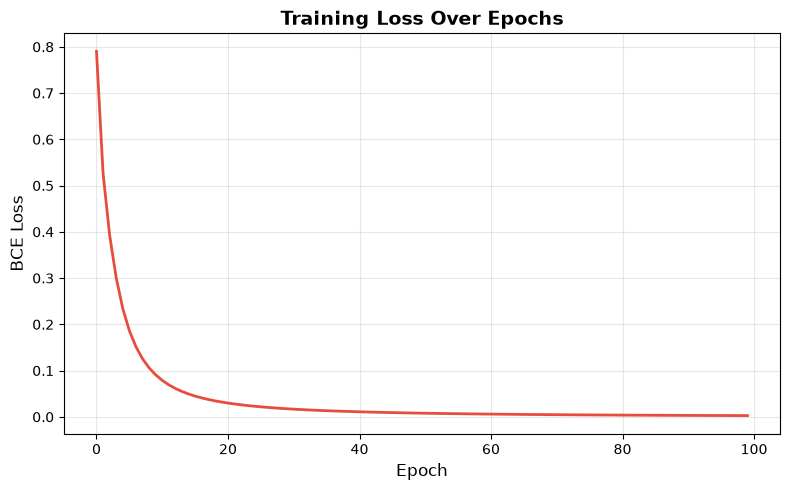

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# --- Generate Synthetic Email Data ---
np.random.seed(42)
n = 600

X = np.column_stack([
    np.concatenate([np.random.poisson(1, 300), np.random.poisson(6, 300)]),
    np.concatenate([np.random.normal(0.05, 0.02, 300), np.random.normal(0.25, 0.08, 300)]),
    np.concatenate([np.random.poisson(2, 300), np.random.poisson(50, 300)]),
    np.concatenate([np.random.poisson(1, 300), np.random.poisson(7, 300)])
]).astype(np.float32)

y = np.concatenate([np.zeros(300), np.ones(300)]).reshape(-1, 1)

# --- Normalize & Split ---
mean, std = X.mean(0), X.std(0)
X = (X - mean) / std

split = 480
X_train = torch.tensor(X[:split])
X_test  = torch.tensor(X[split:])
y_train = torch.tensor(y[:split]).float()
y_test  = torch.tensor(y[split:]).float()

# --- Define Network ---
class SpamClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 8),
            nn.ReLU(),
            nn.Linear(8, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

model = SpamClassifier()
criterion = nn.BCELoss()
optimizer = optim.RMSprop(model.parameters(), lr=0.01)

# --- Train ---
losses = []
for epoch in range(100):
    out = model(X_train)
    loss = criterion(out, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if (epoch+1) % 25 == 0:
        acc = ((out >= 0.5).float() == y_train).float().mean().item()
        print(f"  Epoch {epoch+1:>3}/100 | Loss: {loss.item():.4f} | Acc: {acc:.1%}")

# --- Evaluate ---
with torch.no_grad():
    y_pred = (model(X_test).numpy().flatten() >= 0.5).astype(int)
y_true = y_test.numpy().flatten().astype(int)
acc = np.mean(y_pred == y_true)
tp = np.sum((y_pred==1)&(y_true==1))
tn = np.sum((y_pred==0)&(y_true==0))
fp = np.sum((y_pred==1)&(y_true==0))
fn = np.sum((y_pred==0)&(y_true==1))

print(f"\nTest Accuracy: {acc:.1%}")
print(f"Precision:     {tp/(tp+fp):.1%}")
print(f"Recall:        {tp/(tp+fn):.1%}")

# --- Predict New Emails ---
new = np.array([[0,0.03,1,0],[8,0.30,75,9],[1,0.04,1,0],[12,0.40,100,11]], dtype=np.float32)
new_norm = torch.tensor((new - mean) / std)

with torch.no_grad():
    preds = model(new_norm).numpy().flatten()

print(f"\n  {'Links':>6} {'Caps%':>6} {'Recips':>7} {'SpamW':>6} {'Score':>7} {'Decision':>8}")
print(f"  {'─'*6} {'─'*6} {'─'*7} {'─'*6} {'─'*7} {'─'*8}")
for row, p in zip(new, preds):
    print(f"  {row[0]:>6.0f} {row[1]:>5.0%} {row[2]:>7.0f} {row[3]:>6.0f} {p:>7.3f} {'Spam' if p>=0.5 else 'Legit':>8}")

# --- Loss Curve ---
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(losses, color='#e74c3c', linewidth=2)
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('BCE Loss', fontsize=12)
ax.set_title('Training Loss Over Epochs', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()